In [6]:
%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [7]:
import os
import re
import json
import statistics
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [8]:
load_dotenv()

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file.")

API key found


In [9]:
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())

if AUDIO_PATH.exists():
    print(
        f"Audio found: {AUDIO_PATH.name} "
        f"({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)"
    )
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: c:\Users\sabri\OneDrive\Desktop\Ironhack-bootcamp\Week 3\Day 2 - RAG\lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [10]:
#Transcribe podcast. This cell calls the OpenAI transcription API

import subprocess
import glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with OpenAI and save the result locally."""

    out = Path(out_path)

    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # Split audio into smaller MP3 files
    Path("_pieces").mkdir(exist_ok=True)

    subprocess.run([
        "ffmpeg", "-v", "error", "-y",
        "-i", str(audio_path),
        "-ac", "1",
        "-b:a", "64k",
        "-f", "segment",
        "-segment_time", str(piece_seconds),
        "-reset_timestamps", "1",
        "_pieces/piece_%02d.mp3"
    ], check=True)

    # Transcribe each piece
    from openai import OpenAI

    client = OpenAI()
    texts = []

    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            result = client.audio.transcriptions.create(
                model=model,
                file=fh
            )
            texts.append(result.text)

        print(f, "done")

    # Combine and save transcript
    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")

    return text


podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)

print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])

transcript.txt already exists -> skipping transcription
Podcast transcript length: 16329 chars
So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the 


In [11]:
#LOAD PDF:

PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(
        page.extract_text() or ""
        for page in reader.pages
    )

pdf_text = load_pdf()

print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])

PDF length: 156411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


Step 2 — Fixed-Size Chunking
Objective: Split both texts into chunks of 500 characters, with 50 characters of overlap.

In [12]:
splitter = CharacterTextSplitter(
    separator="",
    chunk_size=500,
    chunk_overlap=50
)

pdf_chunks = splitter.split_text(pdf_text)
podcast_chunks = splitter.split_text(podcast_text)

print("PDF chunks:", len(pdf_chunks))
print("Podcast chunks:", len(podcast_chunks))

PDF chunks: 348
Podcast chunks: 37


In [13]:
#Inspect the chunks:

print("PDF — First chunk:")
print(pdf_chunks[0])

print("\nPDF — Second chunk:")
print(pdf_chunks[1])

print("\nPodcast — First chunk:")
print(podcast_chunks[0])

PDF — First chunk:
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TRUSTWORTHY AI 
 
High-Level Expert Group on Artificial Intelligence 
 
 
 
 
 
 
 
 
This document was written by the High-Level Expert Group on AI (AI HLEG) . The members of the AI HLEG 
named in this document support the overall framework for Trustworthy AI put forward in these Guidelines, 
althoug

PDF — Second chunk:
orthy AI put forward in these Guidelines, 
although they do not necessarily agree with every single statement in the document .  
 
The Trustworthy AI assessment list presented in Chapter III of this document will undergo a piloting phase by 
stakeholders to gather practical feedback. A revised version  of the assessment list, taking into account the 
feedback gathered through the piloting phase, will be presented to the Eu ropean Commission in early 2020. 
 
 
The A

##Analysis Question 1
Does fixed-size chunking break sentences in the middle?

In [14]:
def clean_ending_percentage(chunks):
    clean = sum(
        chunk.rstrip().endswith((".", "?", "!"))
        for chunk in chunks
    )
    return round(100 * clean / len(chunks), 2)

print("PDF clean endings:", clean_ending_percentage(pdf_chunks), "%")
print("Podcast clean endings:", clean_ending_percentage(podcast_chunks), "%")

PDF clean endings: 3.16 %
Podcast clean endings: 5.41 %


**Test different chunk sizes and overlaps**

In [15]:
results = []

for size in [500, 1000, 2000]:
    for overlap in [0, 50, 100]:
        splitter = CharacterTextSplitter(
            separator="",
            chunk_size=size,
            chunk_overlap=overlap
        )

        for name, text in [
            ("PDF", pdf_text),
            ("Podcast", podcast_text)
        ]:
            chunks = splitter.split_text(text)

            results.append({
                "Document": name,
                "Chunk Size": size,
                "Overlap": overlap,
                "Number of Chunks": len(chunks),
                "Clean Endings (%)": clean_ending_percentage(chunks)
            })

df_results = pd.DataFrame(results)
display(df_results)

,Document,Chunk Size,Overlap,Number of Chunks,Clean Endings (%)
0,PDF,500,0,313,2.24
1,Podcast,500,0,33,3.03
2,PDF,500,50,348,3.16
3,Podcast,500,50,37,5.41
4,PDF,500,100,391,3.32
5,Podcast,500,100,41,2.44
6,PDF,1000,0,157,3.18
7,Podcast,1000,0,17,5.88
8,PDF,1000,50,165,3.64
9,Podcast,1000,50,18,5.56


**Analysis Question 2: Paragraph Boundaries**
Objective: Understand how fixed-size chunking handles paragraph breaks.

In [16]:
results = []

for separator in ["", "\n\n"]:
    splitter = CharacterTextSplitter(
        separator=separator,
        chunk_size=500,
        chunk_overlap=50
    )

    for name, text in [
        ("PDF", pdf_text),
        ("Podcast", podcast_text)
    ]:
        chunks = splitter.split_text(text)
        sizes = [len(c) for c in chunks]

        results.append({
            "Document": name,
            "Separator": repr(separator),
            "Chunks": len(chunks),
            "Average Size": round(statistics.mean(sizes), 1),
            "Minimum Size": min(sizes),
            "Maximum Size": max(sizes),
            "Over 500": sum(s > 500 for s in sizes),
            "Paragraph Breaks": text.count("\n\n")
        })

df_paragraphs = pd.DataFrame(results)
display(df_paragraphs)

Created a chunk of size 28061, which is longer than the specified 500
Created a chunk of size 29967, which is longer than the specified 500
Created a chunk of size 23694, which is longer than the specified 500


,Document,Separator,Chunks,Average Size,Minimum Size,Maximum Size,Over 500,Paragraph Breaks
0,PDF,'',348,498.0,258,500,0,3
1,Podcast,'',37,489.6,128,500,0,0
2,PDF,'\n\n',4,39093.0,23693,74680,4,3
3,Podcast,'\n\n',1,16329.0,16329,16329,1,0


**Analysis Question 3: Which content type handles fixed-size chunking better?**
Objective: Compare the PDF and podcast using the same configuration: 500 characters, 50 overlap, separator="".

Fixed-size chunking produces similar chunk sizes for both documents, with an average of 498 characters for the PDF and 489.6 for the podcast. The podcast has slightly more clean sentence endings (5.41% vs. 3.16%), suggesting it handles fixed-size chunking marginally better by this measure. However, both documents frequently have sentences cut in the middle, showing that fixed-size chunking does not preserve sentence boundaries well.

### Step 3: Implement Recursive Character Chunking

Do: Use recursive character splitting, which tries to preserve semantic boundaries.

Do:
1. Use `RecursiveCharacterTextSplitter` (recommended by LangChain)
2. Experiment with chunk sizes: 500, 1000, 2000 tokens
3. Try different separators priority
4. Compare with fixed-size results

In [18]:
recursive_splitter = RecursiveCharacterTextSplitter(
    separators=["\n\n", "\n", " ", ""],
    chunk_size=500,
    chunk_overlap=50
)

pdf_recursive_chunks = recursive_splitter.split_text(pdf_text)
podcast_recursive_chunks = recursive_splitter.split_text(podcast_text)

print("PDF recursive chunks:", len(pdf_recursive_chunks))
print("Podcast recursive chunks:", len(podcast_recursive_chunks))

print("\nPDF clean endings:",
      clean_ending_percentage(pdf_recursive_chunks), "%")

print("Podcast clean endings:",
      clean_ending_percentage(podcast_recursive_chunks), "%")

PDF recursive chunks: 353
Podcast recursive chunks: 37

PDF clean endings: 22.38 %
Podcast clean endings: 13.51 %


In [19]:
import tiktoken

tokenizer = tiktoken.get_encoding("cl100k_base")

results = []

for size in [500, 1000, 2000]:
    splitter = RecursiveCharacterTextSplitter(
        separators=["\n\n", "\n", " ", ""],
        chunk_size=size,
        chunk_overlap=50,
        length_function=lambda text: len(tokenizer.encode(text))
    )

    for name, text in [
        ("PDF", pdf_text),
        ("Podcast", podcast_text)
    ]:
        chunks = splitter.split_text(text)

        results.append({
            "Document": name,
            "Chunk Size (tokens)": size,
            "Chunks": len(chunks),
            "Clean Endings (%)": clean_ending_percentage(chunks)
        })

df_recursive = pd.DataFrame(results)
display(df_recursive)

,Document,Chunk Size (tokens),Chunks,Clean Endings (%)
0,PDF,500,76,34.21
1,Podcast,500,8,12.50
2,PDF,1000,38,28.95
3,Podcast,1000,4,25.00
4,PDF,2000,20,30.00
5,Podcast,2000,2,100.00


In [20]:
separator_options = {
    "Structure-first": ["\n\n", "\n", " ", ""],
    "Word-first": [" ", ""]
}

results = []

for strategy, separators in separator_options.items():
    splitter = RecursiveCharacterTextSplitter(
        separators=separators,
        chunk_size=500,
        chunk_overlap=50
    )

    for name, text in [
        ("PDF", pdf_text),
        ("Podcast", podcast_text)
    ]:
        chunks = splitter.split_text(text)

        results.append({
            "Document": name,
            "Strategy": strategy,
            "Chunks": len(chunks),
            "Average Size": round(
                sum(len(c) for c in chunks) / len(chunks), 1
            ),
            "Clean Endings (%)": clean_ending_percentage(chunks)
        })

df_separators = pd.DataFrame(results)
display(df_separators)

,Document,Strategy,Chunks,Average Size,Clean Endings (%)
0,PDF,Structure-first,353,443.2,22.38
1,Podcast,Structure-first,37,485.3,13.51
2,PDF,Word-first,348,492.2,6.32
3,Podcast,Word-first,37,485.3,13.51


**Conclusion step 3:**

Recursive character chunking performed better than fixed-size chunking at preserving text boundaries. For the PDF, chunks ending with sentence-final punctuation increased from 3.16% to 22.38%, while the podcast improved from 5.41% to 13.51%. The results also show that separator priority matters: structure-first splitting benefits formatted documents, while continuous transcripts show little difference between separator strategies.

**Step 4 — Token-Based Chunking**

In [ ]:
from langchain_text_splitters import TokenTextSplitter

In [21]:
token_splitter = TokenTextSplitter(
    encoding_name="cl100k_base",
    chunk_size=500,
    chunk_overlap=50
)

pdf_token_chunks = token_splitter.split_text(pdf_text)
podcast_token_chunks = token_splitter.split_text(podcast_text)

print("PDF token chunks:", len(pdf_token_chunks))
print("Podcast token chunks:", len(podcast_token_chunks))

PDF token chunks: 71
Podcast token chunks: 8


In [22]:
print("PDF chunk ending:")
print(repr(pdf_token_chunks[0][-100:]))

print("\nPodcast chunk ending:")
print(repr(podcast_token_chunks[0][-100:]))

PDF chunk ending:
'-group-artificial-intelligence).  \nThe reuse policy of European Commission documents is regulated by'

Podcast chunk ending:
'ight. And they have to exist through the entire lifecycle of the system. Not just at launch not just'


In [23]:
token_splitter_1000 = TokenTextSplitter(
    encoding_name="cl100k_base",
    chunk_size=1000,
    chunk_overlap=50
)

pdf_token_chunks_1000 = token_splitter_1000.split_text(pdf_text)
podcast_token_chunks_1000 = token_splitter_1000.split_text(podcast_text)

print("PDF chunks (1000 tokens):", len(pdf_token_chunks_1000))
print("Podcast chunks (1000 tokens):", len(podcast_token_chunks_1000))

PDF chunks (1000 tokens): 34
Podcast chunks (1000 tokens): 4


In [24]:
print("PDF — 500 tokens:",
      clean_ending_percentage(pdf_token_chunks), "%")

print("PDF — 1000 tokens:",
      clean_ending_percentage(pdf_token_chunks_1000), "%")

print("Podcast — 500 tokens:",
      clean_ending_percentage(podcast_token_chunks), "%")

print("Podcast — 1000 tokens:",
      clean_ending_percentage(podcast_token_chunks_1000), "%")

PDF — 500 tokens: 1.41 %
PDF — 1000 tokens: 8.82 %
Podcast — 500 tokens: 12.5 %
Podcast — 1000 tokens: 25.0 %


### Step 6: Visualize and Compare Results

Create visualizations to compare chunking strategies.

In [25]:
import pandas as pd

def chunk_stats(chunks, strategy):
    sizes = [len(chunk) for chunk in chunks]

    return {
        "Strategy": strategy,
        "Avg size (chars)": round(sum(sizes) / len(sizes), 1),
        "Min size": min(sizes),
        "Max size": max(sizes),
        "# Chunks": len(chunks)
    }

pdf_comparison = pd.DataFrame([
    chunk_stats(pdf_chunks, "Fixed-500"),
    chunk_stats(pdf_recursive_chunks, "Recursive-500"),
    chunk_stats(pdf_token_chunks, "Token-500")
])

display(pdf_comparison)

,Strategy,Avg size (chars),Min size,Max size,# Chunks
0,Fixed-500,498.0,258,500,348
1,Recursive-500,443.2,132,498,353
2,Token-500,2443.3,748,2776,71


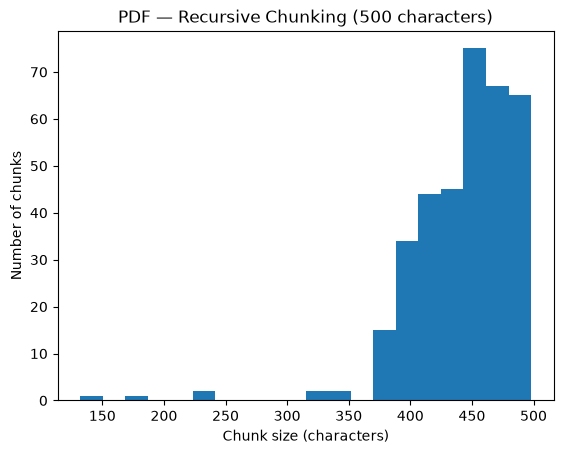

In [26]:
import matplotlib.pyplot as plt

sizes = [len(chunk) for chunk in pdf_recursive_chunks]

plt.hist(sizes, bins=20)
plt.xlabel("Chunk size (characters)")
plt.ylabel("Number of chunks")
plt.title("PDF — Recursive Chunking (500 characters)")
plt.show()

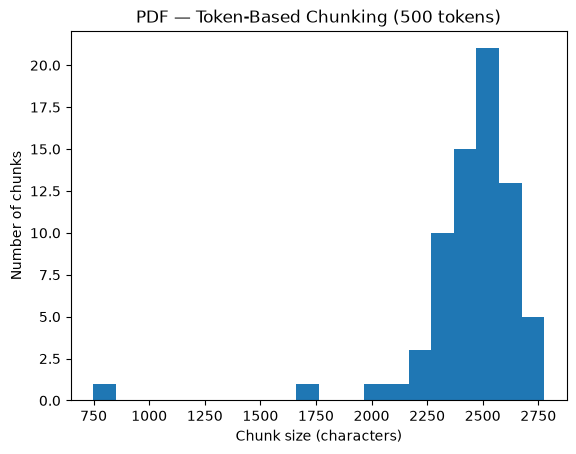

In [27]:
sizes = [len(chunk) for chunk in pdf_token_chunks]

plt.hist(sizes, bins=20)
plt.xlabel("Chunk size (characters)")
plt.ylabel("Number of chunks")
plt.title("PDF — Token-Based Chunking (500 tokens)")
plt.show()

In [28]:
strategies = {
    "Fixed": pdf_chunks,
    "Recursive": pdf_recursive_chunks,
    "Token-based": pdf_token_chunks
}

for strategy, chunks in strategies.items():
    print(f"\n{strategy}:")
    for i, chunk in enumerate(chunks[:3]):
        print(f"Chunk {i + 1}: {repr(chunk[-50:])}")


Fixed:
Chunk 1: 'orthy AI put forward in these Guidelines, \nalthoug'
Chunk 2: 'arly 2020. \n \n \nThe AI HLEG is an independent expe'
Chunk 3: 's. We wish to explicitly and warmly thank all thos'

Recursive:
Chunk 1: 'or Trustworthy AI put forward in these Guidelines,'
Chunk 2: 'esented to the Eu ropean Commission in early 2020.'
Chunk 3: '2018 and was subject to an open consultation which'

Token-based:
Chunk 1: 'y of European Commission documents is regulated by'
Chunk 2: ' list of ethical principles, by providing guidance'
Chunk 3: 'non-discrimination and fairness, (6) environmental'


## Step 6 — Chunking Strategy Trade-offs

### 1. Fixed-Size Chunking

**Advantages:**
- Simple to implement and produces predictable chunk sizes.
- Most chunks were close to the configured limit of 500 characters (average: 498 characters).

**Disadvantages:**
- Frequently breaks words and sentences.
- Does not consider paragraph boundaries or document structure.
- Only 3.16% of PDF chunks ended with sentence-final punctuation.

### 2. Recursive Character Chunking

**Advantages:**
- Attempts to preserve paragraph, line, and word boundaries.
- Produced better sentence-boundary preservation than fixed-size chunking.
- At 500 characters, 22.38% of PDF chunks ended with sentence-final punctuation, compared with 3.16% for fixed-size chunking.

**Disadvantages:**
- Chunk sizes are less uniform because the splitter prioritizes structural boundaries.
- Does not guarantee that sentences or complete ideas remain together.
- Its effectiveness depends on the structure and formatting of the source document.

### 3. Token-Based Chunking

**Advantages:**
- Controls chunk size using tokens rather than characters.
- Helps manage LLM context-window limits and estimate token usage.
- Produces predictable token counts, which is useful for LLM integration.

**Disadvantages:**
- Does not prioritize sentence or paragraph boundaries.
- At 500 tokens, only 1.41% of PDF chunks ended with sentence-final punctuation.
- Can separate related information across chunks.

### 4. Comparison of PDF Results

| Strategy | Average chunk size (characters) | Number of chunks | Clean endings |
|---|---:|---:|---:|
| Fixed-size (500 characters) | 498.0 | 348 | 3.16% |
| Recursive (500 characters) | 443.2 | 353 | 22.38% |
| Token-based (500 tokens) | 2443.3 | 71 | 1.41% |

**Note:** The token-based configuration uses 500 tokens, while the other two use 500 characters. Therefore, their chunk sizes are not directly equivalent.

### 5. Conclusion

Based on these experiments, **recursive character chunking appears to be the most suitable initial strategy for the PDF**.

It preserved text boundaries better than fixed-size chunking. The inspection of chunk endings also showed that recursive splitting generally avoided cutting words, while fixed-size splitting sometimes interrupted them.

Token-based chunking offers better control over LLM token limits but frequently interrupts sentences.

However, **clean sentence endings do not necessarily mean better retrieval performance**.

To confirm which strategy works best in a RAG system, we would need to test each strategy using representative questions and evaluate whether the retrieved chunks contain the information required to answer them correctly.

### Step 7: Analyze Chunk Quality

Do: Evaluate chunk quality by checking boundary preservation.

In [29]:
import pandas as pd

# Calculate the percentage of clean sentence endings
def pct_clean_boundaries(chunks):
    if not chunks:
        return 0.0

    clean = sum(
        1 for chunk in chunks
        if (text := chunk.page_content if hasattr(chunk, "page_content") else chunk).strip().endswith((".", "?", "!"))
    )

    return round(clean / len(chunks) * 100, 2)


# Compare all strategies across both documents
results = [
    ["Fixed-size (500 chars)", "PDF", pdf_chunks],
    ["Fixed-size (500 chars)", "Podcast", podcast_chunks],
    ["Recursive (500 chars)", "PDF", pdf_recursive_chunks],
    ["Recursive (500 chars)", "Podcast", podcast_recursive_chunks],
    ["Token-based (500 tokens)", "PDF", pdf_token_chunks],
    ["Token-based (500 tokens)", "Podcast", podcast_token_chunks]
]

comparison = pd.DataFrame([
    {
        "Strategy": strategy,
        "Document": document,
        "Number of chunks": len(chunks),
        "Clean endings (%)": pct_clean_boundaries(chunks)
    }
    for strategy, document, chunks in results
])

display(comparison)

,Strategy,Document,Number of chunks,Clean endings (%)
0,Fixed-size (500 chars),PDF,348,3.16
1,Fixed-size (500 chars),Podcast,37,5.41
2,Recursive (500 chars),PDF,353,22.38
3,Recursive (500 chars),Podcast,37,13.51
4,Token-based (500 tokens),PDF,71,1.41
5,Token-based (500 tokens),Podcast,8,12.50


## Step 7 — Chunk Quality Analysis

Recursive character chunking achieved the highest percentage of clean sentence endings for both the PDF (22.38%) and podcast transcript (13.51%) among the configurations compared. This suggests that recursive splitting preserves text boundaries better because it prioritizes structural separators instead of splitting strictly by character or token count. However, sentence-ending punctuation is only a proxy for context preservation, and retrieval tests would be needed to determine which strategy produces the most relevant and complete information for a RAG system.

## Step 8 — Chunking Strategy Recommendations

### 1. For PDF Documents

**Recommended Strategy:** Recursive Character Chunking

**Reasoning:**
- Recursive chunking achieved the highest percentage of clean sentence endings for the PDF (22.38%), compared with fixed-size (3.16%) and token-based chunking (1.41%).
- It attempts to preserve paragraph, line, and word boundaries, which is particularly useful for structured documents.
- It reduces the risk of splitting important information across chunks.

**Recommended Starting Configuration:**
- Chunk size: 500 characters
- Chunk overlap: 50 characters
- Separators: `["\n\n", "\n", " ", ""]`

**Limitations:**
- Recursive chunking does not guarantee that complete ideas remain together.
- The recommended configuration is a starting point, not a proven optimum.
- Retrieval tests would be necessary to confirm its effectiveness in a RAG system.

### 2. For Podcast Transcripts

**Recommended Strategy:** Token-Based Chunking (Provisional)

**Reasoning:**
- Podcast transcripts often contain continuous conversational text without clear paragraph boundaries.
- Token-based chunking provides predictable token limits, which is useful when sending retrieved content to an LLM.
- In our experiment, token-based chunking with 500 tokens achieved 12.50% clean endings, compared with 13.51% for recursive chunking at 500 characters.

**Recommended Starting Configuration:**
- Chunk size: 500 tokens
- Chunk overlap: 50 tokens
- Tokenizer: `cl100k_base`

**Limitations:**
- Token-based chunking does not preserve conversational or sentence boundaries automatically.
- The recursive strategy performed slightly better on the clean-ending metric, although the configurations used different size units.
- Further testing is required to determine whether token-based chunking preserves complete conversational ideas and improves retrieval performance.

### 3. Trade-offs Summary

| Strategy | Advantages | Disadvantages | Best Suited For |
|---|---|---|---|
| Fixed-Size | Simple, predictable character lengths, easy to implement | Frequently breaks words and sentences; ignores document structure | Basic experiments and relatively uniform text |
| Recursive | Prioritizes structural boundaries; better sentence-boundary preservation in our experiments | Variable chunk sizes; depends on source formatting | Structured PDFs and documents with identifiable text boundaries |
| Token-Based | Controls token counts; useful for managing LLM context limits | Can interrupt sentences and conversational ideas | LLM integrations requiring predictable token limits |
| Semantic | Aims to group text by meaning rather than fixed length | More computationally expensive; requires additional models and evaluation | Potentially useful for content with frequent topic changes |

**Note:** Semantic chunking was not tested in this lab, so its advantages and disadvantages are theoretical rather than experimental findings.

### 4. Final Recommendation

Based on our experiments, recursive character chunking is the strongest initial choice for the PDF because it achieved the highest percentage of clean sentence endings and better respected document structure.

For the podcast transcript, token-based chunking is a reasonable initial candidate because it provides predictable token limits. However, recursive chunking achieved a slightly higher clean-ending percentage, so the available evidence does not establish token-based chunking as superior.

The results demonstrate that chunking strategies involve trade-offs between text structure, chunk size, and token control. **No strategy can be considered optimal based on chunk statistics alone.**

### 5. Next Steps for Validation

Before using these strategies in a production RAG system, I would:

1. Test recursive and token-based chunking using comparable token budgets.
2. Create representative questions about the PDF and podcast.
3. Evaluate whether retrieved chunks contain the information needed to answer each question.
4. Compare retrieval relevance, answer accuracy, and completeness.
5. Adjust chunk size and overlap based on the results.

**Final Conclusion:** Recursive chunking is the preferred starting strategy for the PDF, while token-based chunking remains a candidate for the podcast. The final selection should be based on retrieval performance and answer quality rather than boundary-preservation metrics alone.

**Test Query:**

In [31]:
# Search for a chunk discussing human oversight
keyword = "human oversight"

matching_chunks = [
    (i, chunk)
    for i, chunk in enumerate(pdf_recursive_chunks)
    if keyword.lower() in chunk.lower()
]

print("Matching chunks:", len(matching_chunks))

if matching_chunks:
    index, chunk = matching_chunks[0]
    print("\nChunk index:", index)
    print("\nSource evidence:\n")
    print(chunk)

Matching chunks: 6

Chunk index: 100

Source evidence:

unjustifiably subordinate, coerce, deceive, manipulate, condition or herd humans. Instead,  they should be designed 
to augment, complement and empower human cognitive, social and cultural skills. The allocation of fu nctions 
between humans and AI systems should follow human -centric design principles and leave meaningful opportunity 
for human choice. This means securing human oversight 28 over work processe s in AI systems. AI systems may also


In [32]:
print("Chunk 101:\n")
print(pdf_recursive_chunks[101])

Chunk 101:

fundamentally change the work  sphere. It should support humans in the working environment, and aim for the 
creation of meaningful work. 
 The principle of prevention of harm  
AI systems should neither cause nor exacerbate harm 29 or otherwise adversely affect human beings .30 This entails 
the protection of human dignity as well as mental and physical integrity. AI systems and the environments in which
